In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import spatialdata as sd
import squidpy as sq
import scanpy as sc
import zarr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from scipy.stats import median_abs_deviation

In [4]:
zarr.config.set({"array.rectilinear_chunks": True})

In [5]:
sc.set_figure_params(frameon=False)
sc.settings.verbosity = 2
plt.rcParams["axes.grid"] = False

In [6]:
zarr_path = "lung_data/xenium_lung.zarr"

In [7]:
sdata = sd.read_zarr(zarr_path)

In [8]:
sdata

SpatialData object, with associated Zarr store: /home/cenk/Withnell_spice/lung_data/xenium_lung.zarr
├── Images
│     ├── 'he_image': DataTree[cyx] (3, 43270, 26720), (3, 21635, 13360), (3, 10817, 6680), (3, 5408, 3340), (3, 2704, 1670)
│     └── 'morphology_focus': DataTree[cyx] (4, 37348, 54086), (4, 18674, 27043), (4, 9337, 13521), (4, 4668, 6760), (4, 2334, 3380)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (37348, 54086), (18674, 27043), (9337, 13521), (4668, 6760), (2334, 3380)
│     └── 'nucleus_labels': DataTree[yx] (37348, 54086), (18674, 27043), (9337, 13521), (4668, 6760), (2334, 3380)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (278328, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (277935, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (278328, 5001)
with coordinate systems:
    ▸ 'global', with elements:
        he_image (Images), morphology

In [9]:
adata = sdata.tables["table"]
adata

AnnData object with n_obs × n_vars = 278328 × 5001
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [10]:
adata.var_names_make_unique()

In [11]:
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=[20], log1p=True)

In [12]:
adata.obs["nucleus_ratio"] = adata.obs["nucleus_area"] / adata.obs["cell_area"]

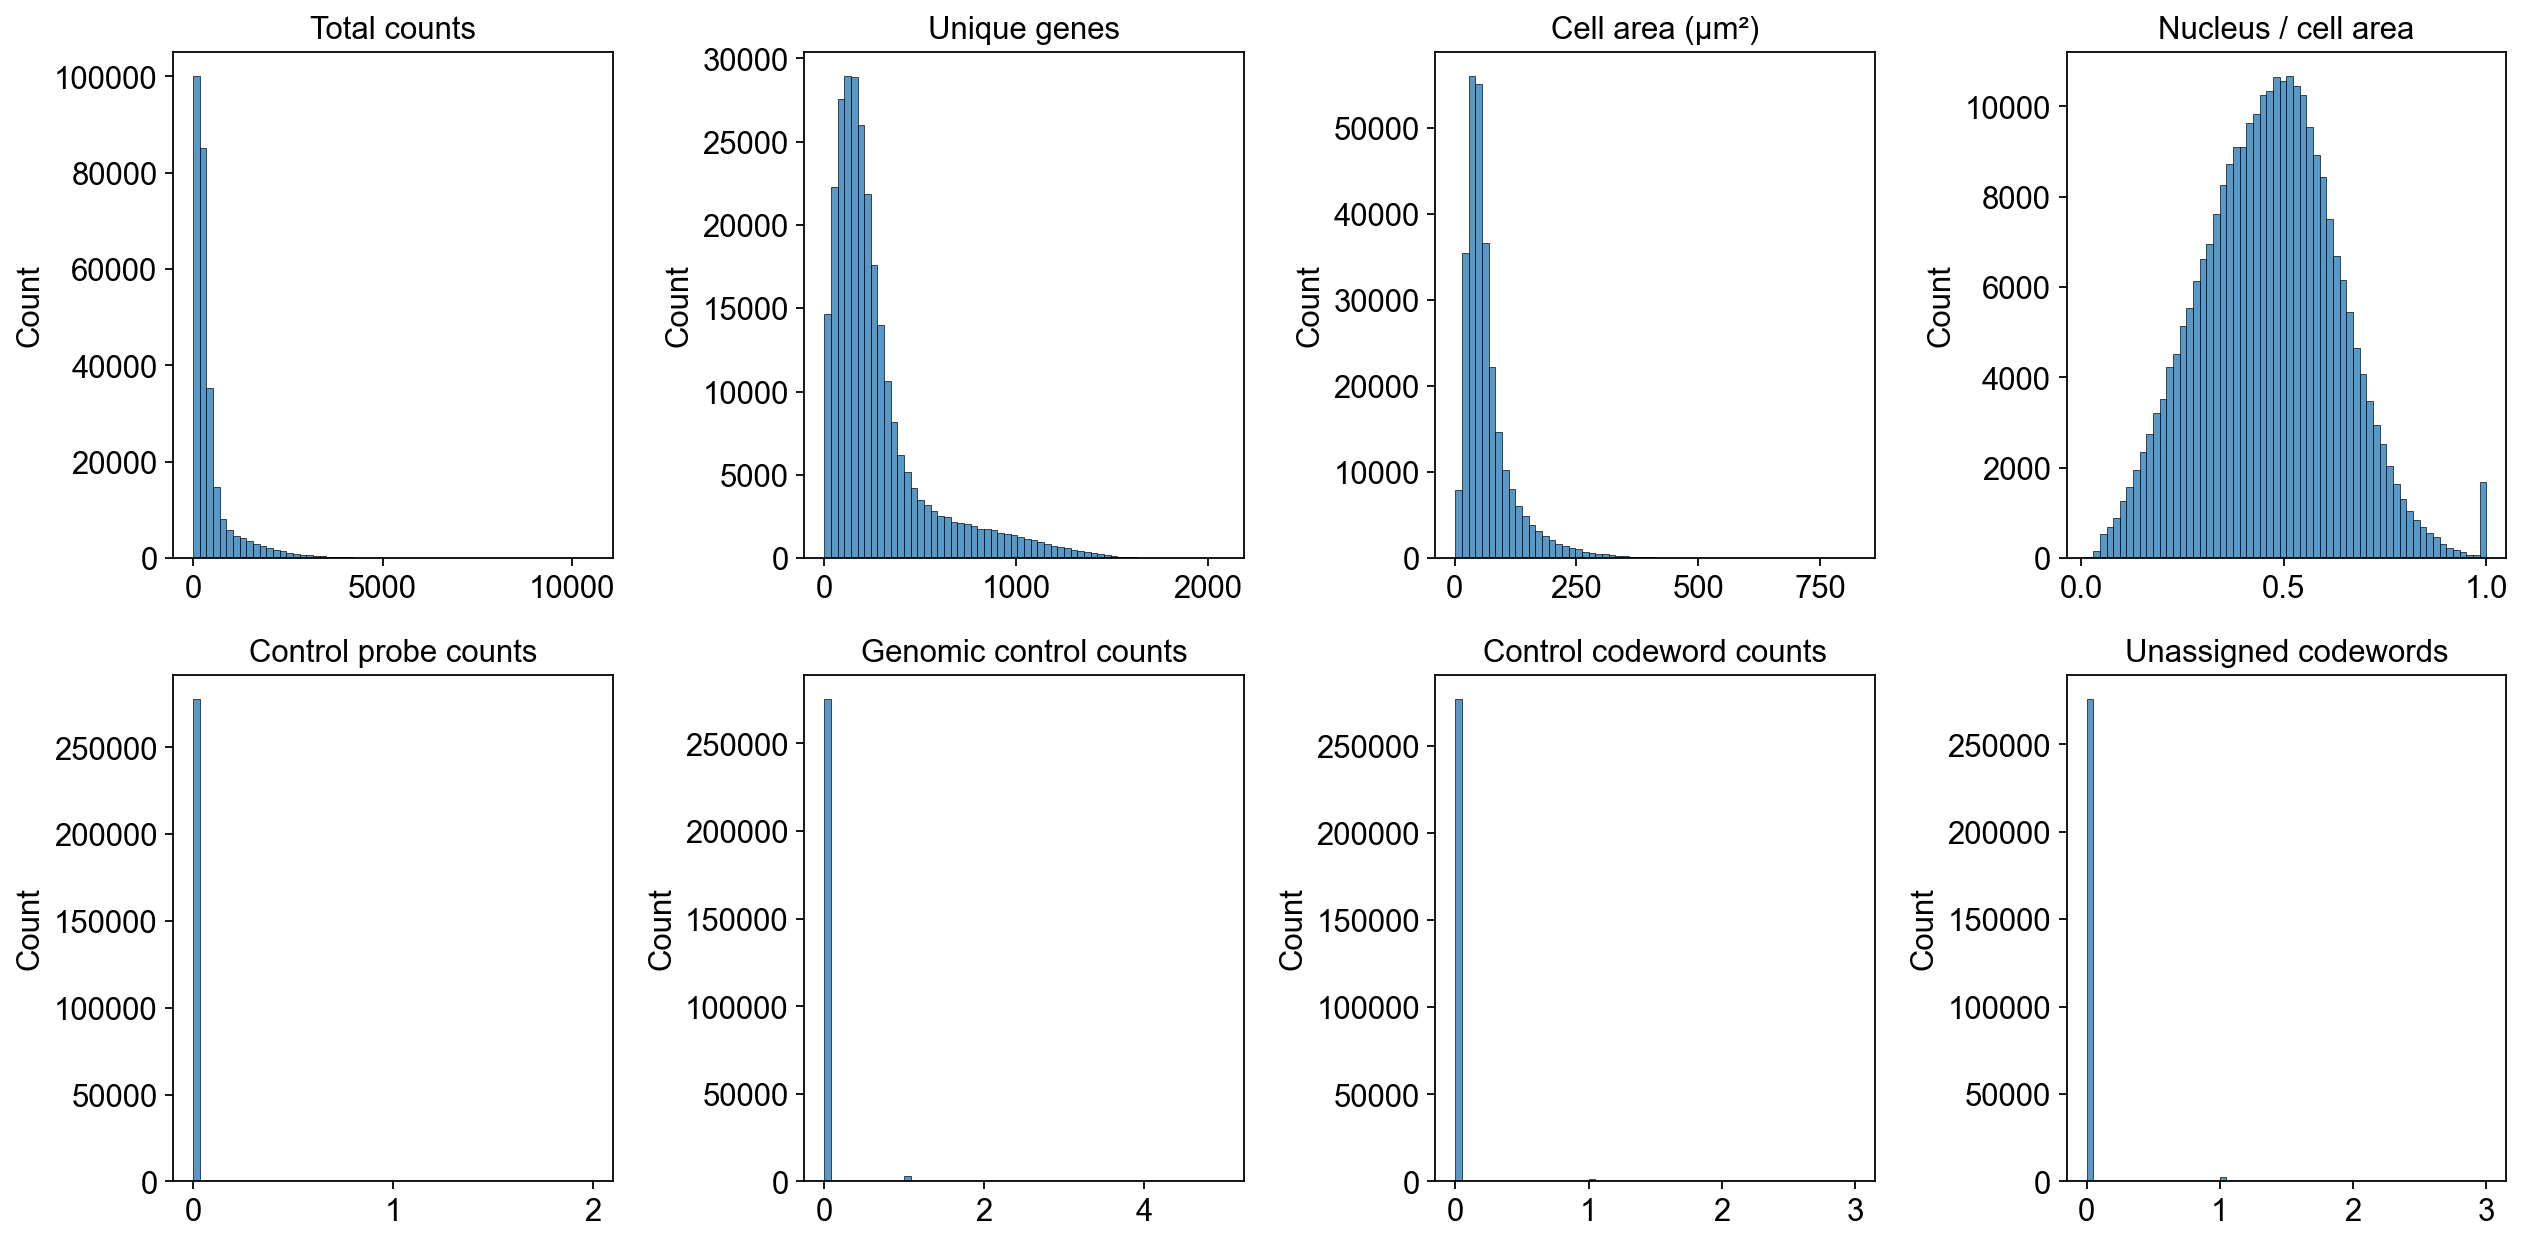

In [13]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8))

pre_qc_panels = [
    ("total_counts",             "Total counts"),
    ("n_genes_by_counts",        "Unique genes"),
    ("cell_area",                "Cell area (µm²)"),
    ("nucleus_ratio",            "Nucleus / cell area"),
    ("control_probe_counts",     "Control probe counts"),
    ("genomic_control_counts",   "Genomic control counts"),
    ("control_codeword_counts",  "Control codeword counts"),
    ("unassigned_codeword_counts","Unassigned codewords"),
]
for ax, (metric, title) in zip(axs.flat, pre_qc_panels):
    sns.histplot(adata.obs[metric], bins=60, kde=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()

In [14]:
print("Nucleus count per cell:")
print(adata.obs["nucleus_count"].value_counts().sort_index().to_string())

Nucleus count per cell:
nucleus_count
0.0      3121
1.0    272679
2.0      2349
3.0       165
4.0        10
5.0         2
6.0         1
7.0         1


In [15]:
def is_outlier(adata, metric: str, nmads: int, upper_only: bool = False):
    M = adata.obs[metric]
    mad = median_abs_deviation(M)
    if upper_only:
        return M > np.median(M) + nmads * mad
    return (M < np.median(M) - nmads * mad) | (M > np.median(M) + nmads * mad)

In [16]:
flags = {
    "low/high counts":        is_outlier(adata, "log1p_total_counts", nmads=5),
    "low/high genes":         is_outlier(adata, "log1p_n_genes_by_counts", nmads=5),
    "high pct top-20 genes":  is_outlier(adata, "pct_counts_in_top_20_genes", nmads=5),
    "cell area":              is_outlier(adata, "cell_area", nmads=5),
    "control probes":         is_outlier(adata, "control_probe_counts", nmads=3, upper_only=True),
    "genomic control":        is_outlier(adata, "genomic_control_counts", nmads=3, upper_only=True),
    "no nucleus":             (adata.obs["nucleus_count"] == 0),
}

adata.obs["outlier"] = np.logical_or.reduce(list(flags.values()))

for name, flag in flags.items():
    print(f"  {name}: {flag.sum():>7,}")
print(f"\n  total outliers (union): {adata.obs['outlier'].sum():>7,} / {adata.n_obs:,}")

  low/high counts:   3,241
  low/high genes:   3,741
  high pct top-20 genes:       0
  cell area:  21,218
  control probes:     518
  genomic control:   2,960
  no nucleus:   3,121

  total outliers (union):  30,433 / 278,328


In [17]:
print(f"Cells before QC: {adata.n_obs:,}")
adata = adata[~adata.obs["outlier"]].copy()

Cells before QC: 278,328


In [18]:
# Calculate 98th percentile threshold
thres = np.quantile(adata.obs["total_counts"], 0.98)

# Subset cells
adata = adata[(adata.obs["total_counts"] >= 20) & (adata.obs["total_counts"] <= thres)].copy()

In [19]:
sc.pp.filter_genes(adata, min_cells=10)

filtered out 2 genes that are detected in less than 10 cells


In [20]:
print(f"Cells after QC:  {adata.n_obs:,}  ({adata.n_obs / 278328 * 100:.1f}% retained)")

Cells after QC:  240,158  (86.3% retained)


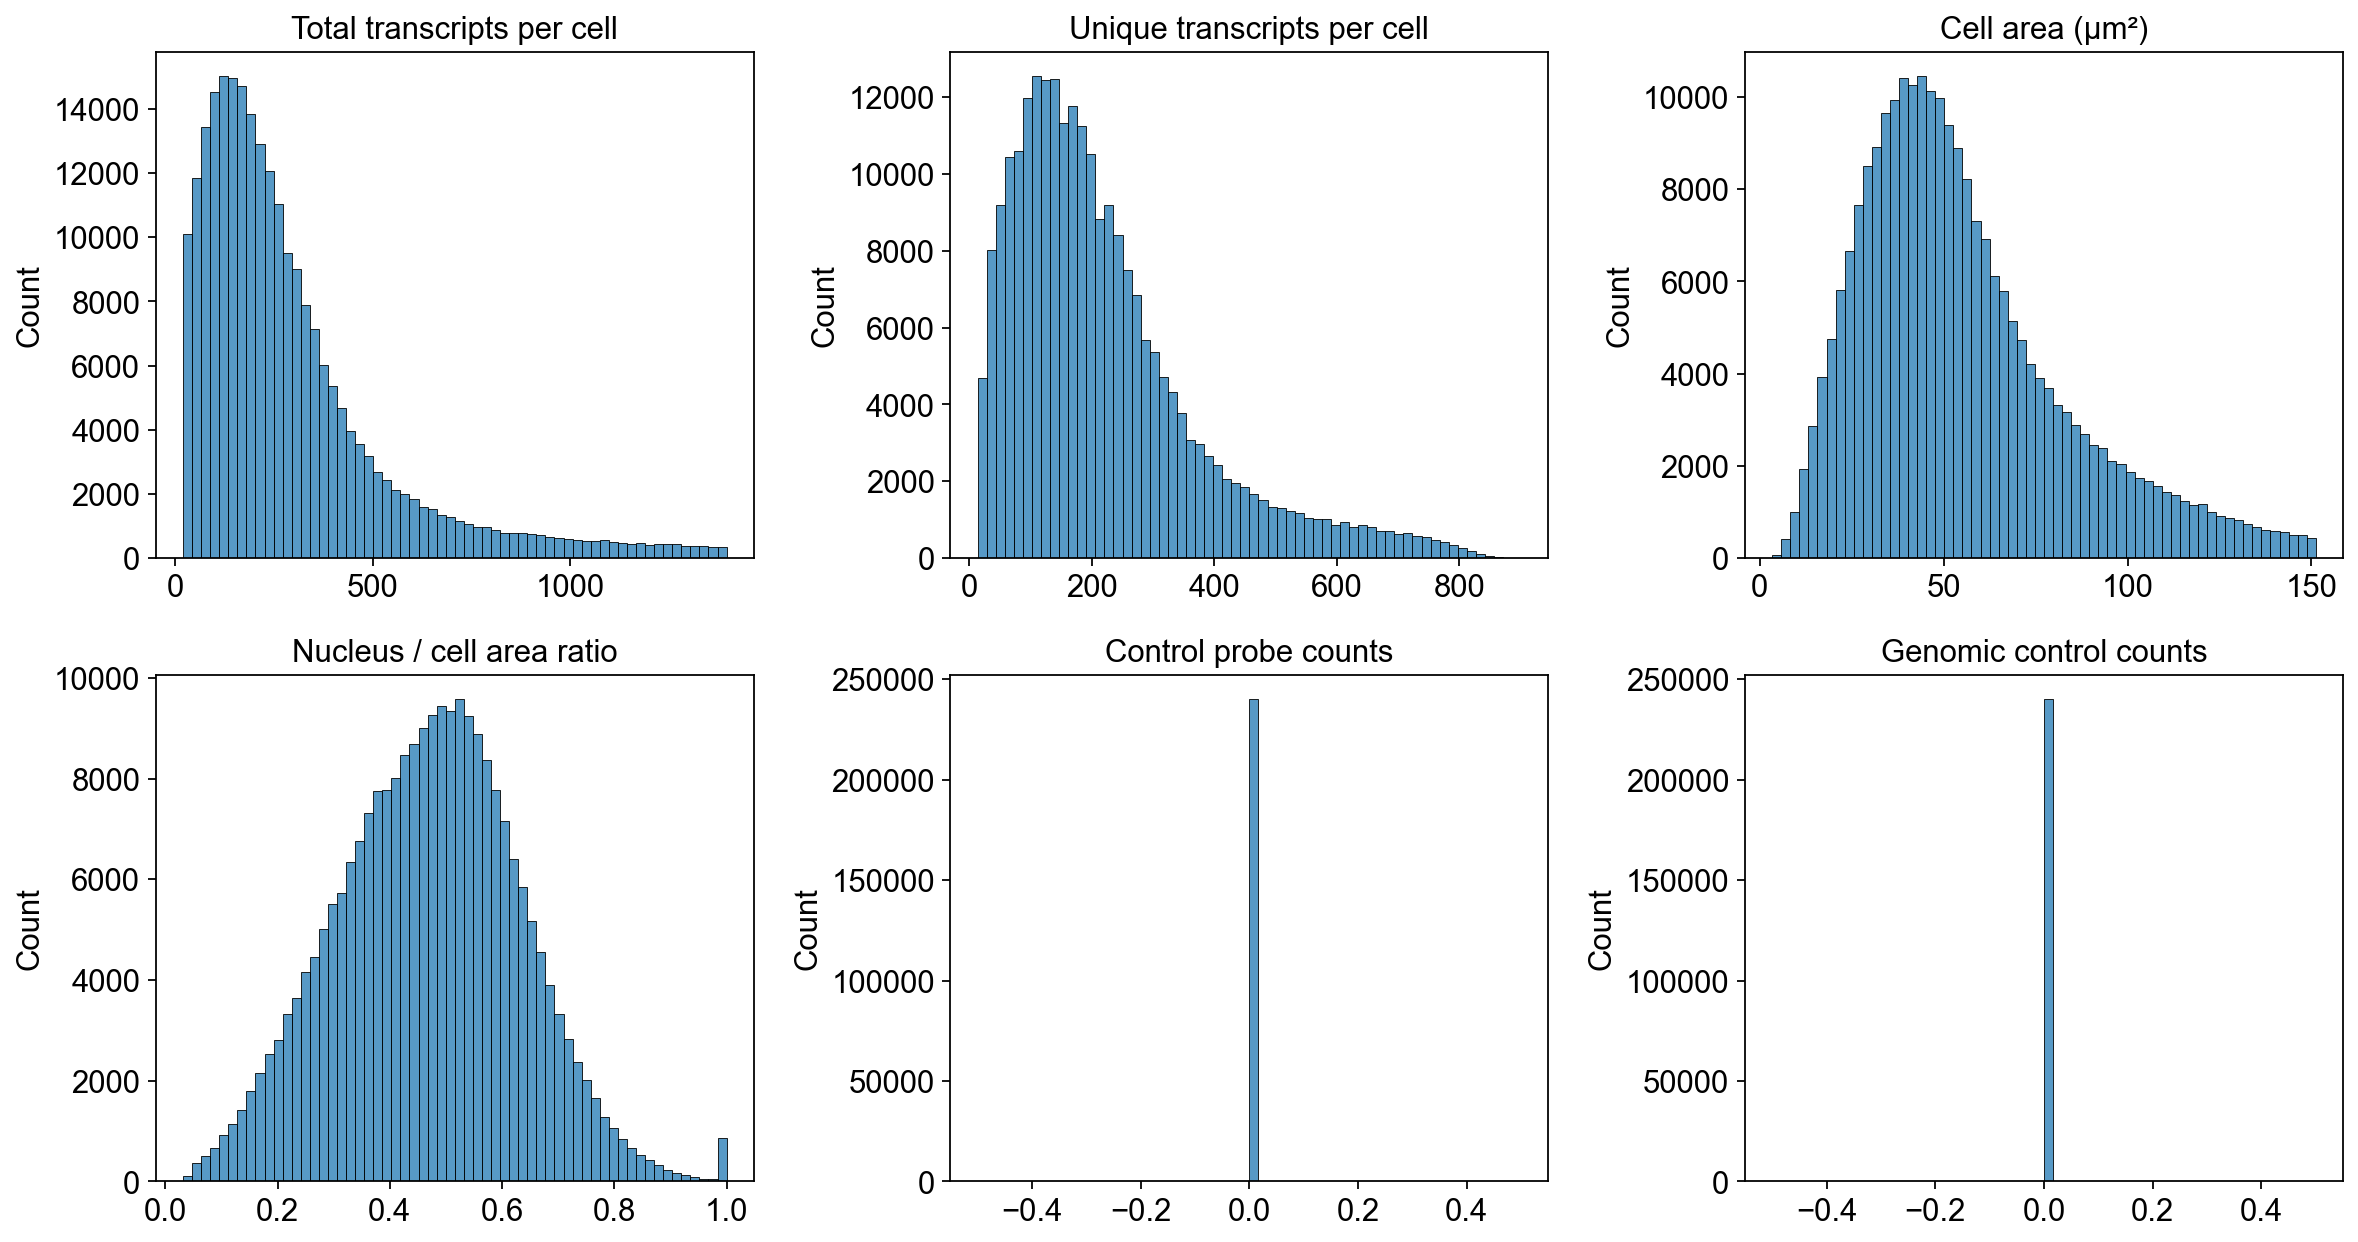

In [21]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))

post_qc_panels = [
    ("total_counts",           "Total transcripts per cell"),
    ("n_genes_by_counts",      "Unique transcripts per cell"),
    ("cell_area",              "Cell area (µm²)"),
    ("nucleus_ratio",          "Nucleus / cell area ratio"),
    ("control_probe_counts",   "Control probe counts"),
    ("genomic_control_counts", "Genomic control counts"),
]
for ax, (metric, title) in zip(axs.flat, post_qc_panels):
    sns.histplot(adata.obs[metric], bins=60, kde=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()

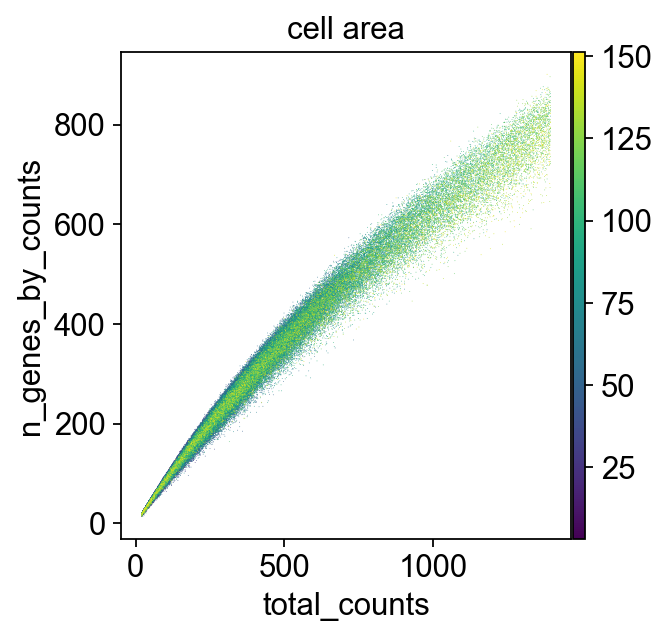

In [22]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="cell_area")

In [23]:
adata.layers["counts"] = adata.X.copy()

In [24]:
sc.pp.normalize_total(adata, target_sum=np.median(adata.obs["total_counts"]))
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:00)


In [25]:
adata.layers["log1p_norm"] = adata.X.copy()

In [26]:
sc.pp.highly_variable_genes(adata, layer="log1p_norm", n_top_genes=2000, flavor="seurat_v3")
adata.var["highly_variable"].value_counts()

extracting highly variable genes


highly_variable
False    2999
True     2000
Name: count, dtype: int64

In [27]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

In [28]:
# sc.pp.regress_out(adata, ["total_counts"], layer="log1p_norm", n_jobs=10)
sc.pp.scale(adata_hvg)

computing PCA
    with n_comps=50
    finished (0:00:06)


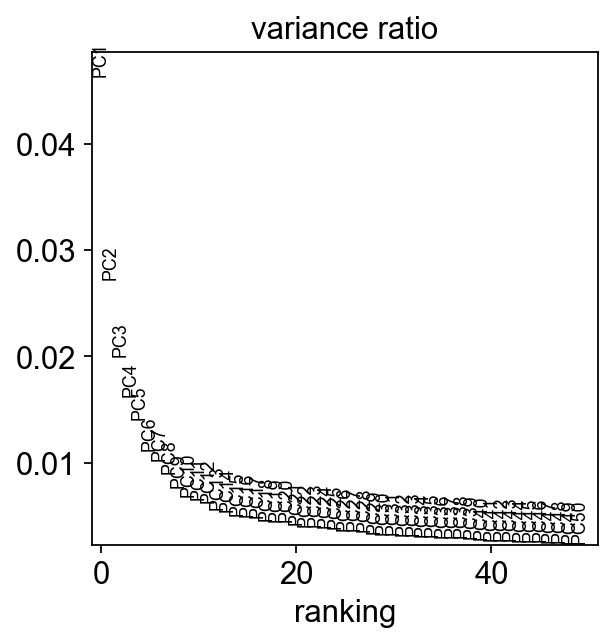

In [29]:
sc.pp.pca(adata_hvg, layer="log1p_norm")
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50)

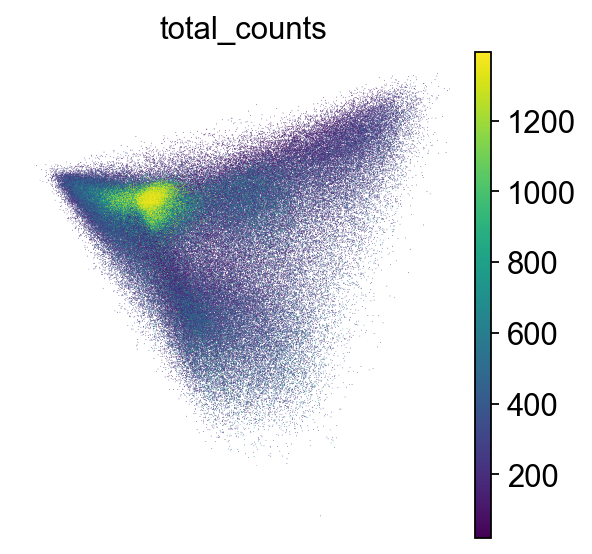

In [30]:
sc.pl.pca(adata_hvg, color="total_counts")

In [31]:
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]

In [32]:
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30)

computing neighbors


    using 'X_pca' with n_pcs = 20
    finished (0:01:08)


In [33]:
sc.tl.umap(adata)

computing UMAP
    finished (0:05:01)


In [34]:
sc.tl.leiden(adata, resolution=0.5, flavor="igraph")
print("Number of clusters: ", adata.obs["leiden"].nunique())

running Leiden clustering
    finished (0:02:21)
Number of clusters:  14


In [35]:
if "leiden_colors" in adata.uns:
    adata.uns.pop("leiden_colors")

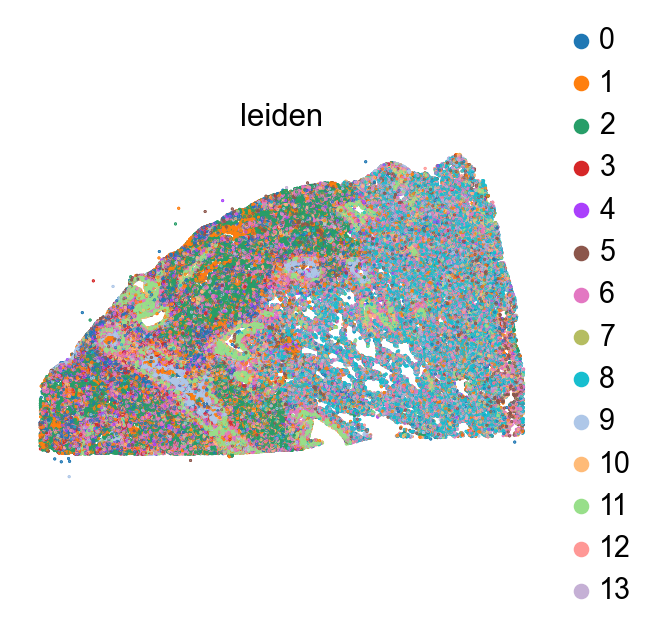

In [36]:
sq.pl.spatial_scatter(
    adata,
    shape=None,
    color="leiden",
)

## Pseudobulk DEG Analysis (PyDESeq2, Leiden clusters, one-vs-rest)

In [37]:
import numpy as np
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
import scipy.sparse as sp

In [38]:
N_REPLICATES = 3
np.random.seed(0)

counts_matrix = adata.layers["counts"]  # raw integer counts, cells x genes
leiden_labels = adata.obs["leiden"].values
clusters = adata.obs["leiden"].cat.categories.tolist()

print(f"Leiden clusters: {clusters}")
print(f"Running 1-vs-rest pseudobulk DEG with {N_REPLICATES} pseudoreplicates each")

Leiden clusters: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13']
Running 1-vs-rest pseudobulk DEG with 3 pseudoreplicates each


In [39]:
all_results = {}
inference = DefaultInference(n_cpus=8)

for cluster in clusters:
    print(f"\n--- Cluster {cluster} ---")

    cluster_idx = np.where(leiden_labels == cluster)[0]
    rest_idx    = np.where(leiden_labels != cluster)[0]

    # Assign each cell to one of N_REPLICATES pseudoreplicates
    cluster_reps = np.random.choice(N_REPLICATES, size=len(cluster_idx))
    rest_reps    = np.random.choice(N_REPLICATES, size=len(rest_idx))

    rows, meta = [], []
    for rep in range(N_REPLICATES):
        for grp, idx_all, rep_arr, label in [
            ("cluster", cluster_idx, cluster_reps, "cluster"),
            ("rest",    rest_idx,    rest_reps,    "rest"),
        ]:
            idx = idx_all[rep_arr == rep]
            if len(idx):
                vec = np.asarray(counts_matrix[idx].sum(axis=0)).flatten()
            else:
                vec = np.zeros(adata.n_vars, dtype=float)
            rows.append(vec)
            meta.append({"condition": label, "replicate": rep})

    pseudobulk_df = pd.DataFrame(
        np.array(rows, dtype=np.int64),
        columns=adata.var_names,
    )
    metadata_df = pd.DataFrame(meta)
    metadata_df.index = pseudobulk_df.index.astype(str)
    pseudobulk_df.index = metadata_df.index

    # Drop genes with fewer than 10 summed counts across all pseudo-samples
    keep = pseudobulk_df.sum(axis=0) >= 10
    pseudobulk_df = pseudobulk_df.loc[:, keep]
    print(f"  cells: cluster={len(cluster_idx):,}  rest={len(rest_idx):,}  genes kept: {keep.sum()}")

    try:
        dds = DeseqDataSet(
            counts=pseudobulk_df,
            metadata=metadata_df,
            design_factors="condition",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stat_res = DeseqStats(
            dds,
            contrast=["condition", "cluster", "rest"],
            inference=inference,
            quiet=True,
        )
        stat_res.summary()
        results = stat_res.results_df.dropna(subset=["padj"]).sort_values("padj")
        all_results[cluster] = results
        n_sig = (results["padj"] < 0.05).sum()
        print(f"  significant DEGs (padj<0.05): {n_sig}")
    except Exception as e:
        print(f"  ERROR: {e}")
        all_results[cluster] = pd.DataFrame()

print("\nDone.")


--- Cluster 0 ---
  cells: cluster=45,830  rest=194,328  genes kept: 4999


  significant DEGs (padj<0.05): 4125

--- Cluster 1 ---
  cells: cluster=25,832  rest=214,326  genes kept: 4999
  significant DEGs (padj<0.05): 3879

--- Cluster 2 ---
  cells: cluster=21,976  rest=218,182  genes kept: 4999
  significant DEGs (padj<0.05): 4367

--- Cluster 3 ---
  cells: cluster=9,681  rest=230,477  genes kept: 4999
  significant DEGs (padj<0.05): 3327

--- Cluster 4 ---
  cells: cluster=5,646  rest=234,512  genes kept: 4999
  significant DEGs (padj<0.05): 2821

--- Cluster 5 ---
  cells: cluster=3,328  rest=236,830  genes kept: 4999
  significant DEGs (padj<0.05): 2481

--- Cluster 6 ---
  cells: cluster=36,728  rest=203,430  genes kept: 4999
  significant DEGs (padj<0.05): 3869

--- Cluster 7 ---
  cells: cluster=682  rest=239,476  genes kept: 4999
  significant DEGs (padj<0.05): 398

--- Cluster 8 ---
  cells: cluster=30,419  rest=209,739  genes kept: 4999
  significant DEGs (padj<0.05): 3734

--- Cluster 9 ---
  cells: cluster=12,730  rest=227,428  genes kept: 4999

In [40]:
# Top 5 upregulated markers per cluster (by log2FC, padj < 0.05)
top_markers = {}
for cluster, res in all_results.items():
    if res.empty:
        top_markers[cluster] = []
        continue
    sig_up = res[(res["log2FoldChange"] > 1) & (res["padj"] < 0.05)]
    sig_up = sig_up.sort_values("log2FoldChange", ascending=False)
    top_markers[cluster] = sig_up.head(5).index.tolist()

for c, genes in top_markers.items():
    print(f"Cluster {c}: {genes}")

Cluster 0: ['MS4A1', 'CXCR5', 'GZMK', 'PAX5', 'BLK']
Cluster 1: ['MARCO', 'IL1RN', 'MMP12', 'OLR1', 'SIGLEC1']
Cluster 2: ['NMU', 'NELL1', 'HS6ST2', 'TMPRSS11E', 'GABBR2']
Cluster 3: ['MZB1', 'TNFRSF17', 'FCRL5', 'DERL3', 'POU2AF1']
Cluster 4: ['CCR8', 'TNFRSF9', 'IL21', 'FOXP3', 'TNFRSF18']
Cluster 5: ['TRPC5', 'SULT2A1', 'NPSR1', 'DDX53', 'KPRP']
Cluster 6: ['COMP', 'SVEP1', 'PI16', 'COL10A1', 'IGFN1']
Cluster 7: ['KLK6', 'PCK1', 'CMTM5', 'SOX10', 'ANGPTL7']
Cluster 8: ['CA4', 'SLC6A4', 'VIPR1', 'FENDRR', 'TMEM100']
Cluster 9: ['ALOX15', 'DNAH2', 'MUC5B', 'DNAH9', 'TEKT1']
Cluster 10: ['PLVAP', 'SELE', 'CCL14', 'SELP', 'CCL16']
Cluster 11: ['CASQ2', 'KCNA5', 'PLN', 'LDB3', 'JPH2']
Cluster 12: ['CRTAC1', 'F11', 'LRP2', 'ALPL', 'PCSK9']
Cluster 13: ['UPK3B', 'BDNF', 'TENT5B', 'LAMA3', 'CLDN18']


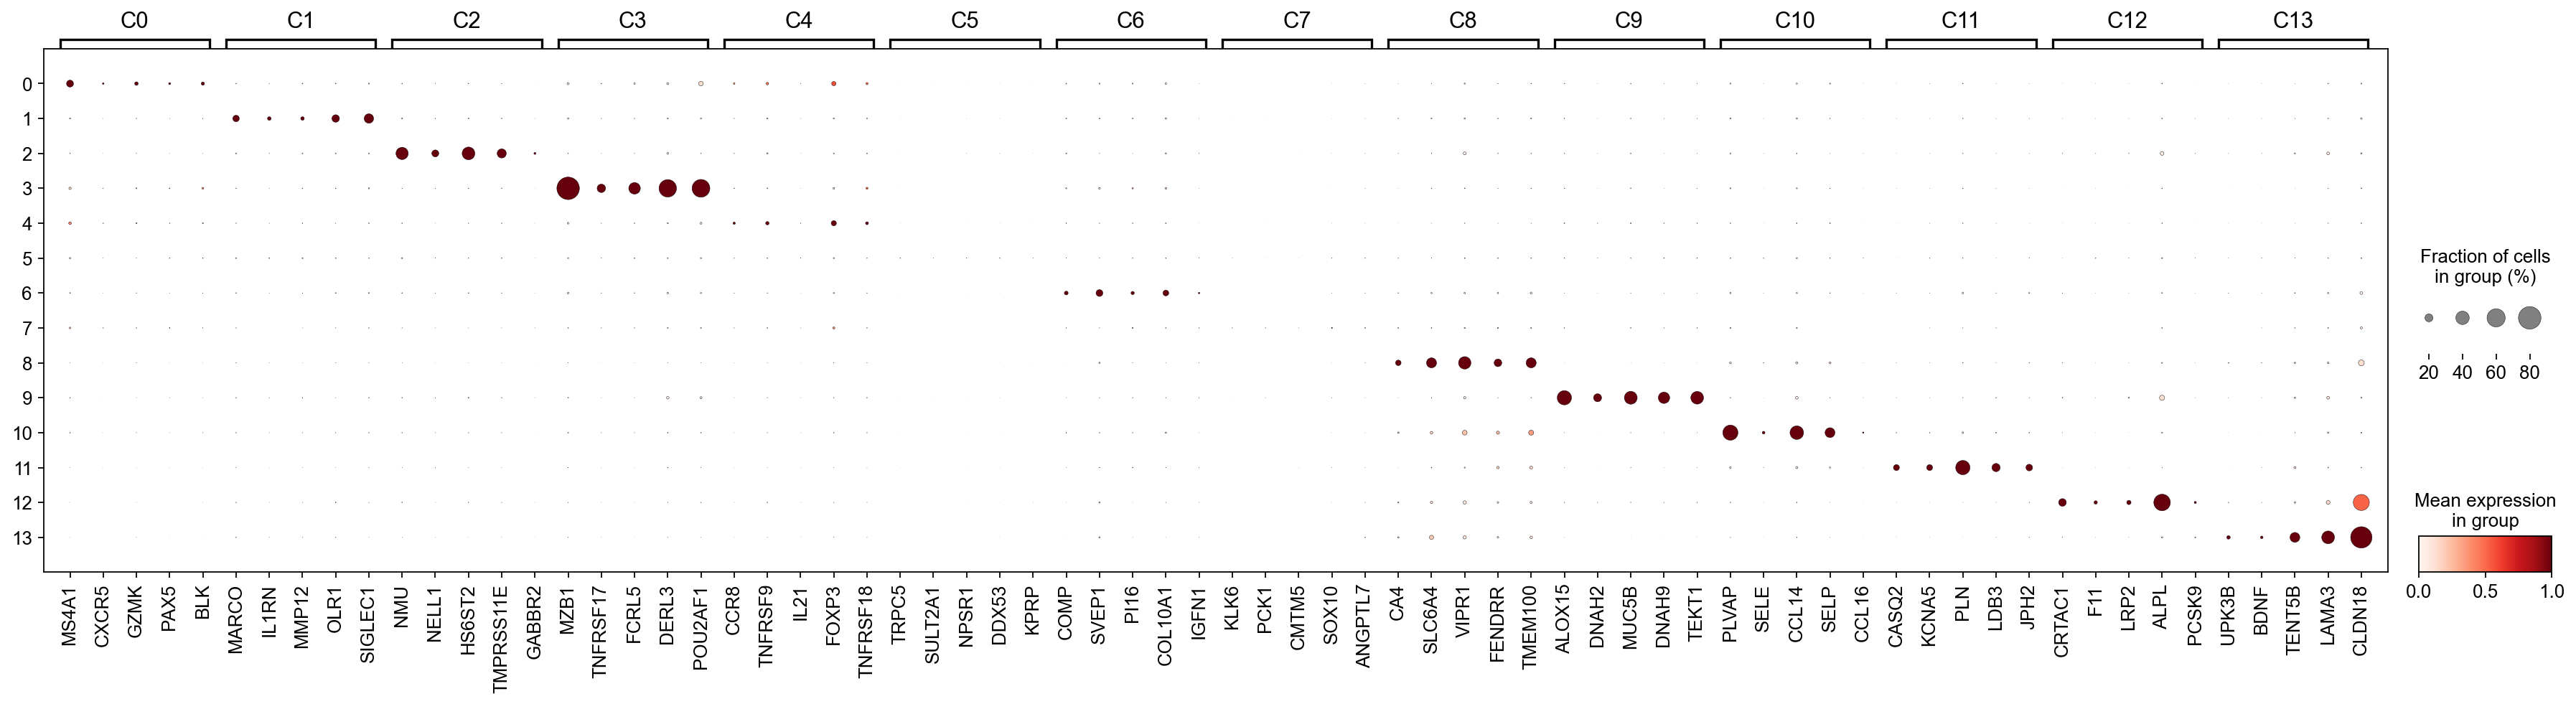

In [41]:
# Build ordered var_names dict: cluster label -> gene list (skip empty clusters)
marker_dict = {
    f"C{c}": genes
    for c, genes in top_markers.items()
    if genes
}

sc.pl.dotplot(
    adata,
    var_names=marker_dict,
    groupby="leiden",
    standard_scale="var",
    dot_max=0.8,
    figsize=(max(12, len(marker_dict) * 2), 6),
    show=True,
    save="lung_top5_markers.pdf",
)

In [42]:
import decoupler as dc

In [43]:
markers = dc.op.resource("PanglaoDB", organism="human")

markers = markers[
    markers["human"].astype(bool)
    & markers["canonical_marker"].astype(bool)
    & (markers["human_sensitivity"].astype(float) > 0.5)
    & (
        markers["organ"].isin(
            ["Lungs", "Immune system", "Vasculature", "Connective tissue", "Smooth muscle"]
        )
    )
]

# Remove duplicated entries
markers = markers[~markers.duplicated(["cell_type", "genesymbol"])]
# remove "Red pulp macrophages" due to too many markers
markers = markers[markers["cell_type"] != "Red pulp macrophages"]
markers = markers[markers["cell_type"] != "Gamma delta T cells"]
# Format
markers = markers.rename(columns={"cell_type": "source", "genesymbol": "target"})
markers = markers[["source", "target"]]

    using data matrix X directly
Storing dendrogram info using `.uns['dendrogram_leiden']`


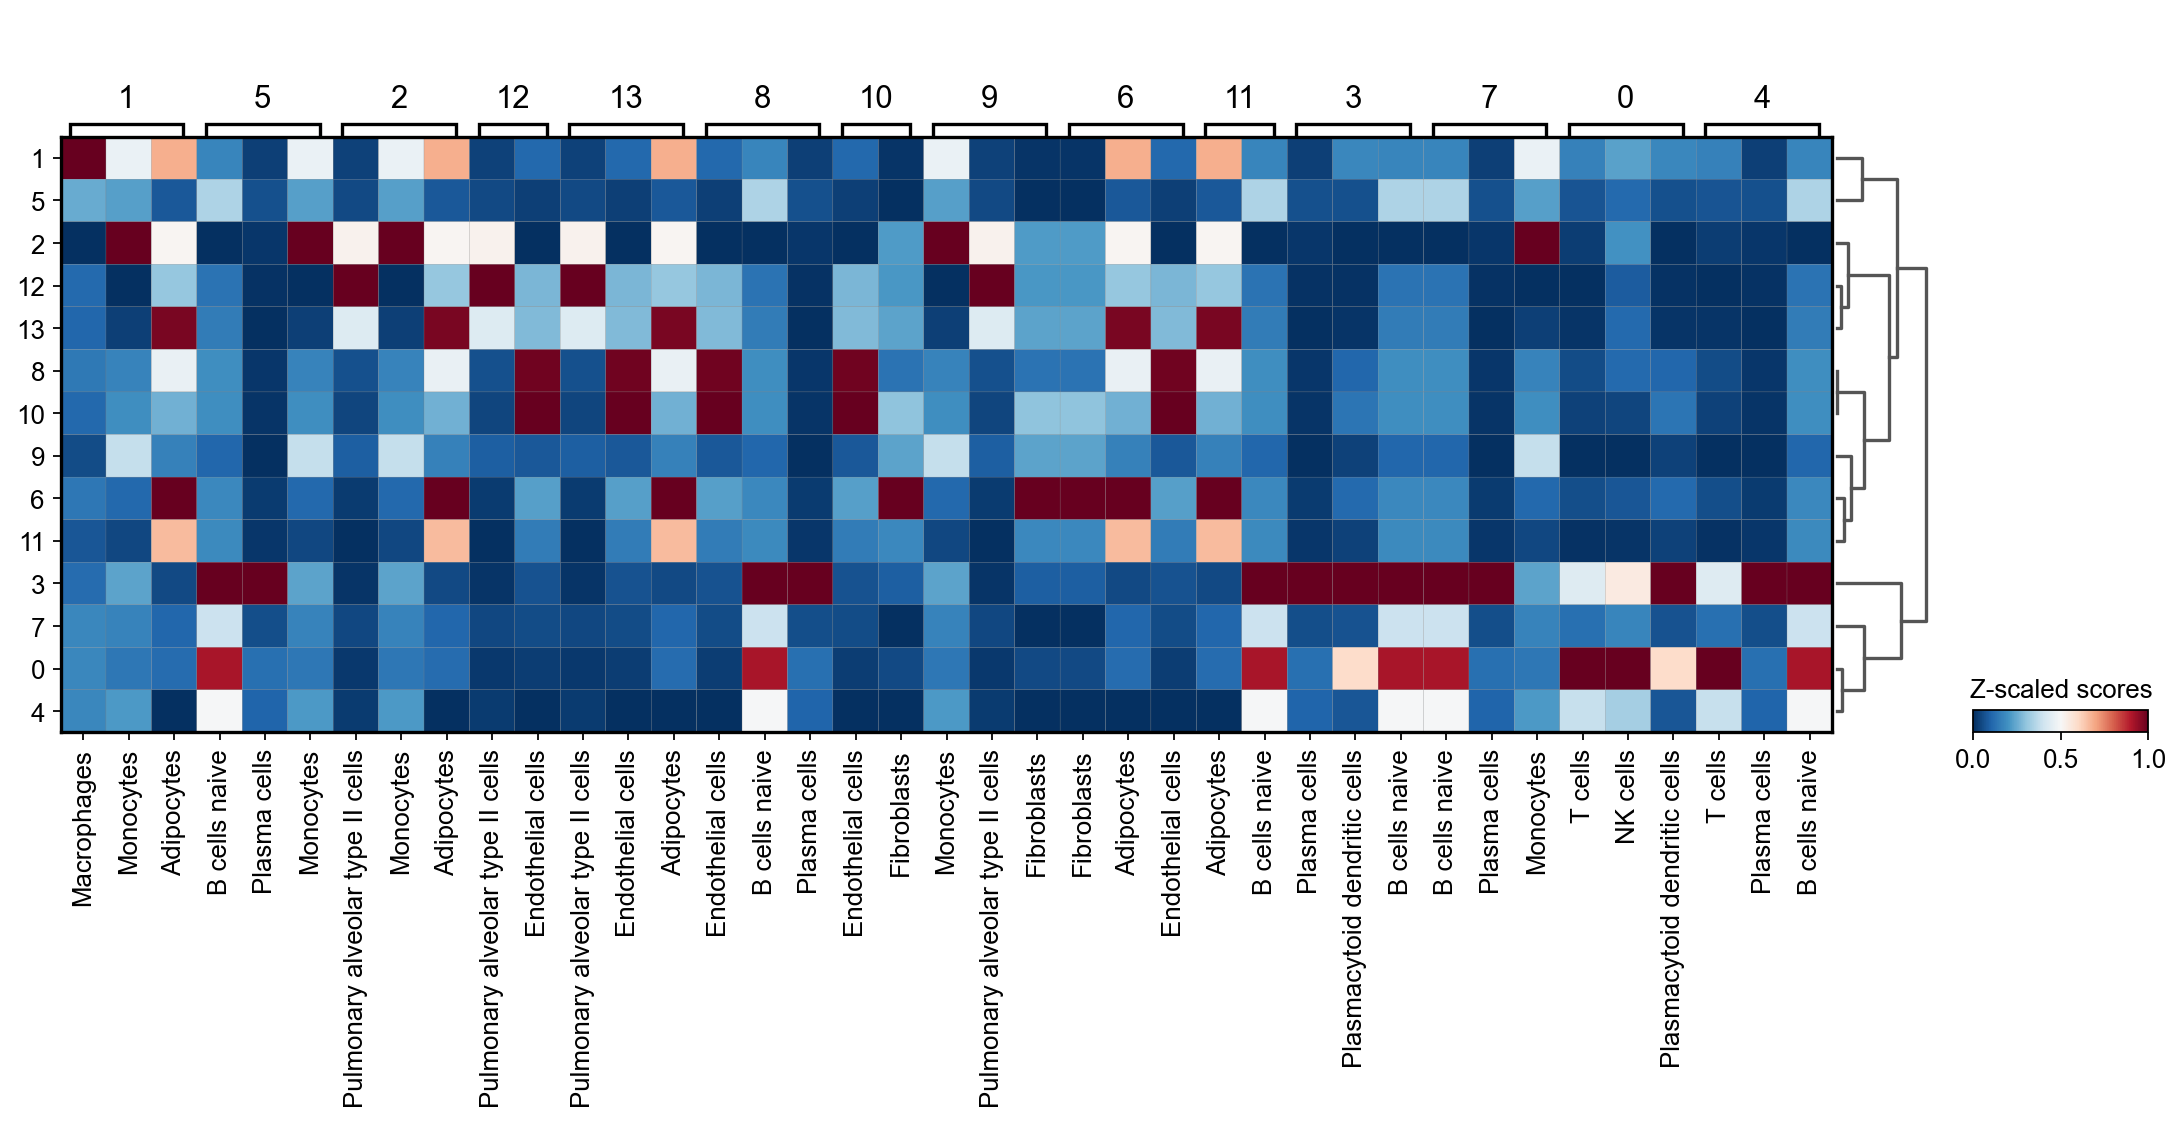

In [44]:
dc.mt.ulm(data=adata, net=markers, layer="log1p_norm")
score = dc.pp.get_obsm(adata, key="score_ulm")

df = dc.tl.rankby_group(score, groupby="leiden", reference="rest", method="wilcoxon")
df = df[df["stat"] > 0]

n_ctypes = 3
ctypes_dict = (
    df.groupby("group")
    .head(n_ctypes)
    .groupby("group")["name"]
    .apply(lambda x: list(x))
    .to_dict()
)

sc.tl.dendrogram(score, groupby="leiden", n_pcs=20)
sc.pl.matrixplot(
    adata=score,
    var_names=ctypes_dict,
    groupby="leiden",
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap="RdBu_r",
)

In [45]:
annotation_dict = (
    df.loc[df.groupby("group")["padj"].idxmin()].set_index("group")["name"].to_dict()
)
annotation_dict

{'0': 'T cells',
 '1': 'Macrophages',
 '10': 'Endothelial cells',
 '11': 'Adipocytes',
 '12': 'Pulmonary alveolar type II cells',
 '13': 'Pulmonary alveolar type II cells',
 '2': 'Pulmonary alveolar type II cells',
 '3': 'Plasma cells',
 '4': 'T cells',
 '5': 'B cells naive',
 '6': 'Fibroblasts',
 '7': 'B cells naive',
 '8': 'Endothelial cells',
 '9': 'Monocytes'}

In [46]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", layer="log1p_norm")

ranking genes


    finished (0:01:31)


    using 'X_pca' with n_pcs = 20
Storing dendrogram info using `.uns['dendrogram_leiden']`


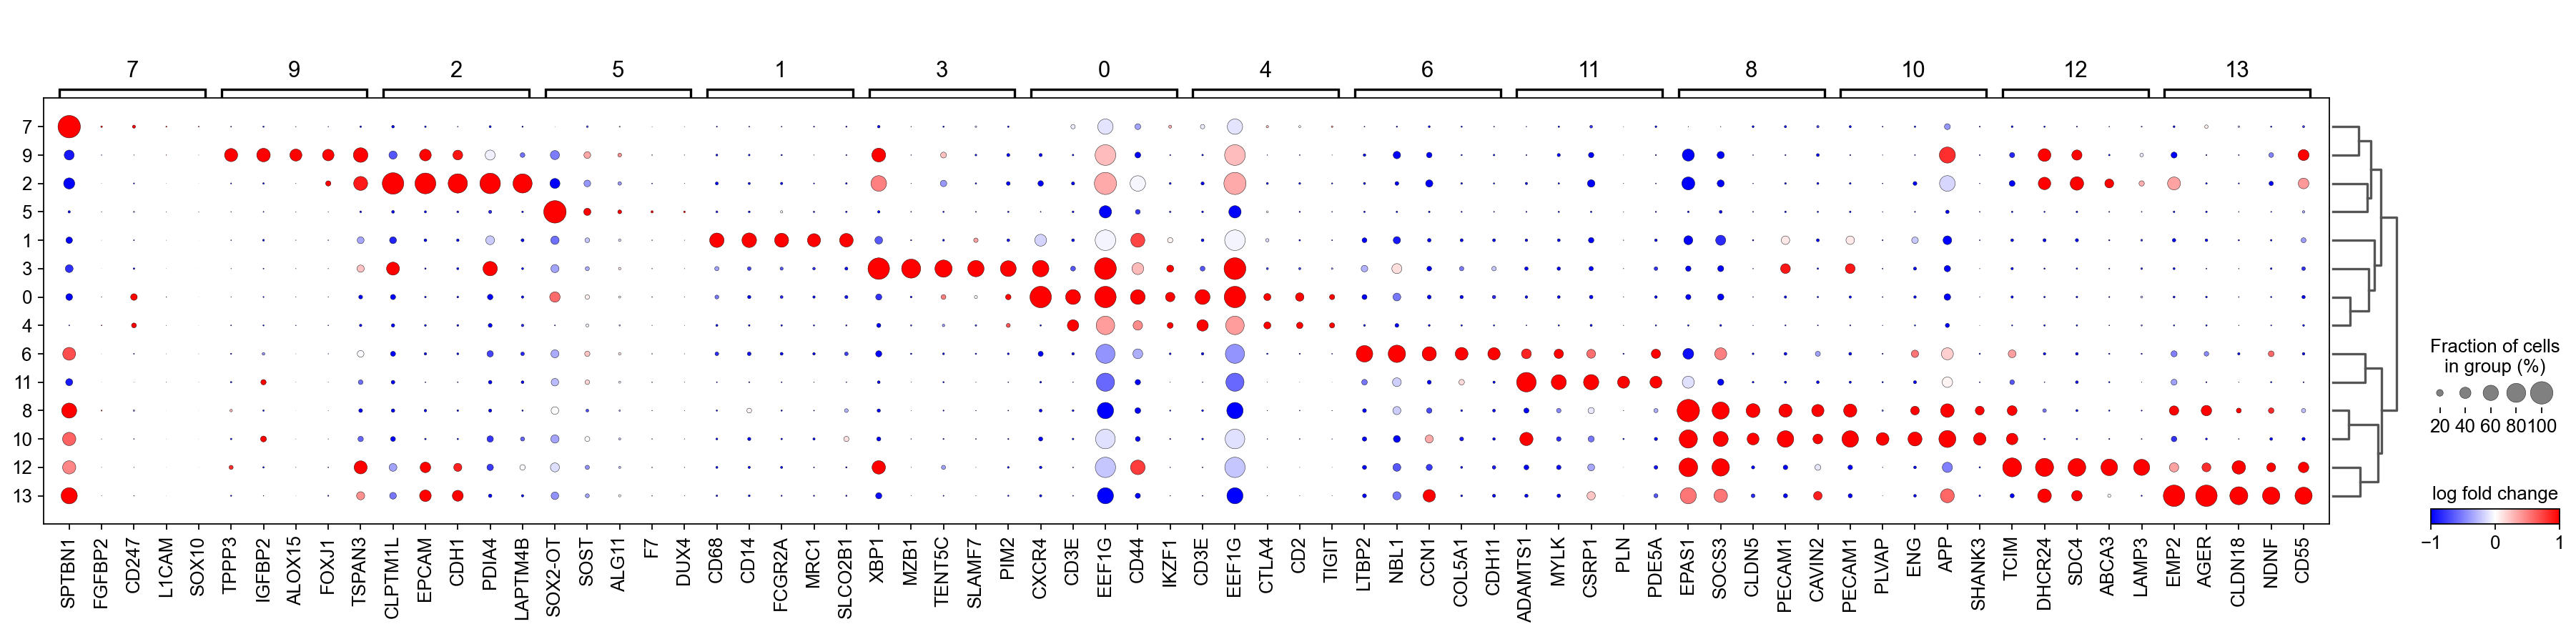

In [47]:
sc.tl.dendrogram(adata, groupby="leiden", n_pcs=20)
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden",
    n_genes=5,
    cmap="bwr",
    values_to_plot="logfoldchanges",
    vmin=-1,
    vmax=1,
)

In [48]:
# get top 10 gene expression for each leiden cluster
degs = sc.get.rank_genes_groups_df(adata, group=None)
degs = degs.groupby("group").head(10)
degs

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CXCR4,290.938629,4.310795,0.0,0.0
1,0,CD3E,176.730072,4.066919,0.0,0.0
2,0,EEF1G,152.391815,1.110223,0.0,0.0
3,0,CD44,102.514626,1.413981,0.0,0.0
4,0,IKZF1,88.807831,2.970684,0.0,0.0
...,...,...,...,...,...,...
64992,13,RTKN2,85.817001,4.443465,0.0,0.0
64993,13,ICAM1,82.454666,2.736313,0.0,0.0
64994,13,ANXA2,78.525757,1.803193,0.0,0.0
64995,13,SLC39A8,78.470566,4.035252,0.0,0.0


In [49]:
annotation_dict = {
    "0": "T cells",
    "1": "Macrophages",
    "2": "Epithelial tumour cells",
    "3": "Plasma cells",
    "4": "Regulatory T cells",
    "5": "Low-quality / unassigned",
    "6": "Fibroblasts",
    "7": "NK cells",
    "8": "Endothelial cells",
    "9": "Ciliated epithelial cells",
    "10": "Endothelial cells (activated/plvap+)",
    "11": "Pericytes",
    "12": "Alveolar type II epithelial cells",
    "13": "Alveolar type I epithelial cells",
}

In [50]:
adata.obs["cell_type"] = [annotation_dict[cluster] for cluster in adata.obs["leiden"]]
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

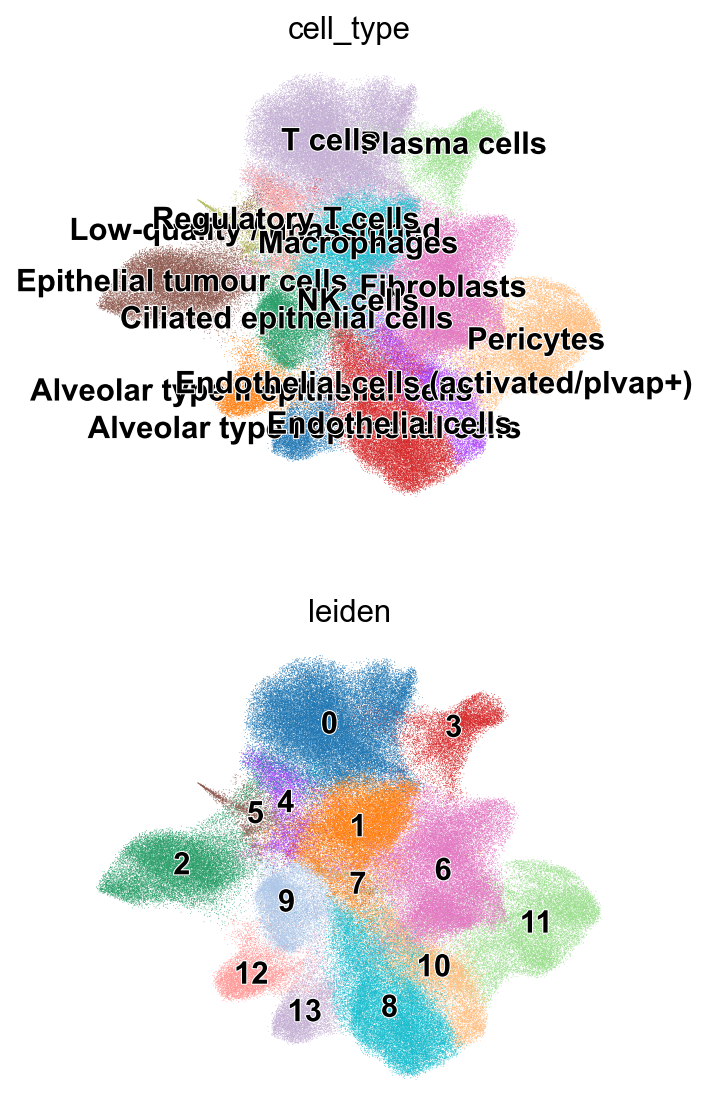

In [51]:
sc.pl.umap(
    adata=adata,
    color=["cell_type", "leiden"],
    ncols=1,
    legend_loc="on data",
    legend_fontoutline=1,
)

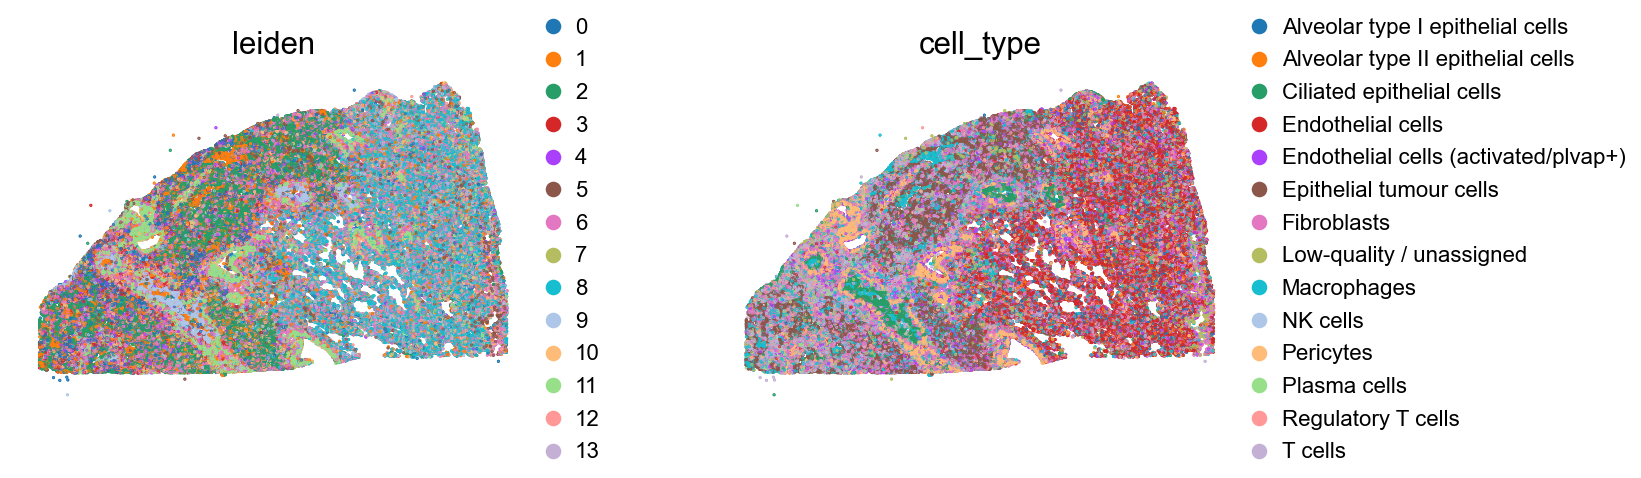

In [52]:
sq.pl.spatial_scatter(
    adata,
    color=["leiden", "cell_type"],
    wspace=0.25,
    shape=None
)

In [53]:
adata.write_h5ad("processed_data/xenium_lung_annotated.h5ad")